# Lesson 14: Localized Mass Transfer
The concept of mass transfer in electrochemical reactions has been vaguely introduced thus far, with reference to the fact that we work in 2-dimensions rather than 3-dimensions. This lesson will expand on this concept.

Today's topics:
- Modes of mass transfer
- Concentration profiles
- diffusion limited currents

**Reference:**
- Chapter 4 and Section 1.4 in *Electrochemical Methods: Fundamentals and Applications*, Allen J. Bard & Larry R. Faulkner.

---

## Configure Environment

In [8]:
import sys
if '../Resources' not in sys.path:
    sys.path.append('../Resources')     # so that echem.py can be found

import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, widgets

import echem                            # the shared toolkit for this course
from echem import R, T, F, f, WIDE      # constants and the two-panel figure size
echem.use_style()                       # course-wide graph formatting

rng = np.random.default_rng(0)          # fixed seed: the cartoons look the same every run

Recall the **Butler-Volmer equation** from [Lesson 11](L11-Kinetics-I-ButlerVolmer.ipynb):


$
\large i = F A k^0 \left[ C_R(0,t)e^{(1-\alpha) F (E-E^{0'}) / R T} -  C_O(0,t)e^{-\alpha F (E-E^{0'}) / R T} \right]
$

It was stated that the equation captures three important phenomena for electrochemical experiments. These were:

1. kinetics: k0
2. thermo: E - E0'
3. mass transfer: Cj(0,t)

<div class="alert alert-block alert-info">
<b>Question:</b> Before scrolling further, think about what can influence the concentration of O ($C_O(0,t)$) and R ($C_R(0,t)$) at the electrode surface besides voltage. Write down your ideas.
</div>

# 1. Modes of Mass Transfer

Electrons can only be transferred as fast as redox active species can be delivered to the electrode surface. The species O and R may be neutral, or they may be ionic. We must consider all factors that may influence the movement of these species through a solution. There are three phenomena that must be considered.

## Mode of Mass Transfer #1

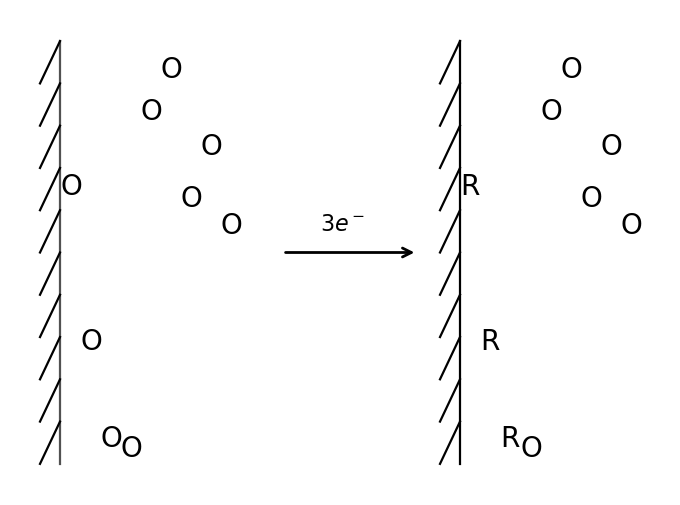

In [9]:
# Cartoon: diffusion carries O towards the electrode and R away from it
fig = plt.figure()
ax = plt.subplot(111)
ax.set_xlim(-0.2, 3)
ax.grid(visible=False)
ax.axes.set_axis_off()
ax.plot([0, 0], [0, 1], [2, 2], [0, 1], 'black')
for i in range(10):
    ax.plot([-0.1, 0], [0.1*i, 0.1 + 0.1*i], 'black')
    ax.plot([1.9, 2], [0.1*i, 0.1 + 0.1*i], 'black')

heights = rng.uniform(size=9)
N_REACTED = 3                           # the three molecules nearest the surface react
for i, height in enumerate(heights):
    ax.annotate('O', (i*0.1, height))
    ax.annotate('R' if i < N_REACTED else 'O', xy=(i*0.1 + 2, height))

ax.annotate('', fontsize=8,
            xy=(1.1, 0.5), xycoords='data',
            xytext=(1.8, 0.5), textcoords='data',
            arrowprops=dict(arrowstyle='<-', color='black'))
ax.annotate(rf'${N_REACTED}e^-$', xy=(1.3, 0.55), fontsize=8)
fig.savefig('../Workspace/diffusion.png')

## Diffusion

The transfer of electrons at an electrode surface changes the solution composition in a thin 2-D slice, generating a concentration gradient. Concentration gradients drive mass transfer, as described by **Fick's laws of diffusion**.

<div class="alert alert-block alert-success">
<b>Fick's First Law:</b> Matter will diffuse from a region of high concentration to a region of low concentration with a magnitude of flux that is proportional to the concentration gradient.
</div>

In mathematical terms, the flux (rate of mass transfer; $J(x,t)$) is:

$
\large J_j(x,t) = -D_j \frac{\delta C_j(x,t)}{\delta x}
$

Where:
- $D_j$: the diffusion coefficient for species $j$ (cm$^2$ s$^{-1}$)
- $C_j$: the concentration of species $j$
- $x$: distance from electrode

From the electrochemical perspective, we can therefore expect that larger currents yield greater concentration gradients, which yield faster mass transfer. This will happen in all 3-dimensions of the electrolyte solution. It therefore has to be specified that this flux is a function of both space ($x$ = distance from electrode) and time ($t$). Diffusion ALWAYS happens, there is no avoiding it. All mathematical representations that accurately represent electrochemical behavior must therefore consider it.

## Mode of Mass Transfer #2

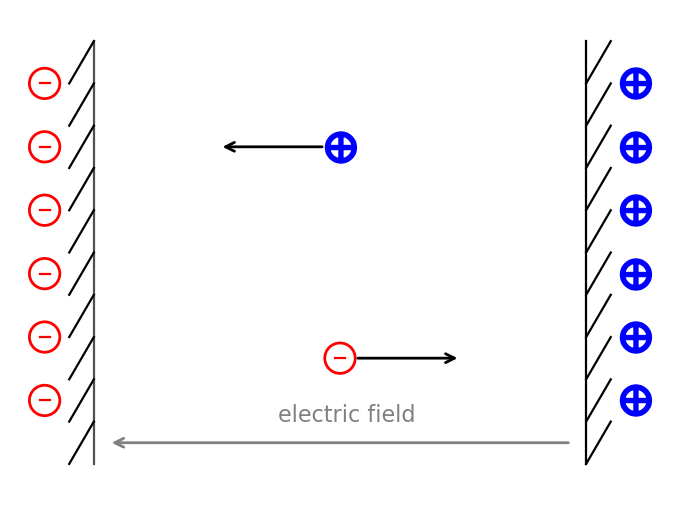

In [10]:
# Cartoon: migration drives ions through the electric field between the electrodes
fig = plt.figure()
ax = plt.subplot(111)
ax.set_xlim(-0.3, 2.3)
ax.grid(visible=False)
ax.axes.set_axis_off()
ax.plot([0, 0], [0, 1], [2, 2], [0, 1], 'black')
for i in range(10):
    ax.plot([-0.1, 0], [0.1*i, 0.1 + 0.1*i], 'black')
    ax.plot([2., 2.1], [0.1*i, 0.1 + 0.1*i], 'black')

# charge held on the two electrode surfaces
levels = [0.9, 0.75, 0.6, 0.45, 0.3, 0.15]
ax.scatter([2.2]*6, levels, facecolors='blue', edgecolors='blue',
           marker=r'$\bigoplus$', s=120)
ax.scatter([-0.2]*6, levels, facecolors='none', edgecolors='red', s=120)
for level in levels:
    ax.plot([-0.22, -0.18], [level, level], color='red')

# one cation and one anion moving in the field
ax.scatter(1, 0.75, facecolors='blue', edgecolors='blue', marker=r'$\bigoplus$', s=120)
ax.scatter(1, 0.25, facecolors='none', edgecolors='red', s=120)
ax.plot([0.98, 1.02], [0.25, 0.25], color='red')
ax.annotate('', fontsize=8, xy=(1.05, 0.25), xycoords='data',
            xytext=(1.5, 0.25), textcoords='data',
            arrowprops=dict(arrowstyle='<-', color='black'))
ax.annotate('', fontsize=8, xy=(0.95, 0.75), xycoords='data',
            xytext=(0.5, 0.75), textcoords='data',
            arrowprops=dict(arrowstyle='<-', color='black'))
ax.annotate('', fontsize=8, xy=(1.95, 0.05), xycoords='data',
            xytext=(0.05, 0.05), textcoords='data',
            arrowprops=dict(arrowstyle='<-', color='gray'))
ax.annotate('electric field', (0.75, 0.1), color='gray', fontsize=8)

fig.savefig('../Workspace/migration.png')

## Migration

Electrochemical reactions inherently involve a change in charge of the species of interest. The application of a voltage between the working electrode and the counter/auxiliary electrode generates an electric field across the cell. This electric field forces the movement of ionic species via **migration**.

<div class="alert alert-block alert-success">
<b>Migration:</b> The movement of charged species when they are placed in an electric field.
</div>

Mathematically, the flux caused by migration is: 

$
\large J_j(x,t) = -\frac{z_j}{RT}FD_jC_j \frac{\delta \phi(x,t)}{\delta x}
$

Where:
- $z_j$: charge on ionic species (ie, +1 for H$^+$)
- $C_j$: concentration of charged species
- $D_j$: diffusion coefficient for the charged species
- $\delta\phi(x,t)/\delta x$: potential gradient (i.e. the electric field), in units of *V distance*$^{-1}$

Migration will increase/decrease the rate of mass transfer by attracting/repelling charged reactants and products -- a negative voltage will attract cations but repel anions. The behavior depends on so many variables that are difficult to control that it becomes a problem to deal with. Typical experiments will therefore seek to minimize the flux due to migration by adding excess electrolyte to the electrochemical solution. Addition of >100x the concentration of an **electrolyte species** (a chemical that breaks into solvated ions in solution) compared to the analyte of interest results in the migration flux being carried by this (hopefully) unreactive pair of ions. The effect of migration is therefore often ignored in electrochemical equations -- but not always!

## Mode of Mass Transfer #3

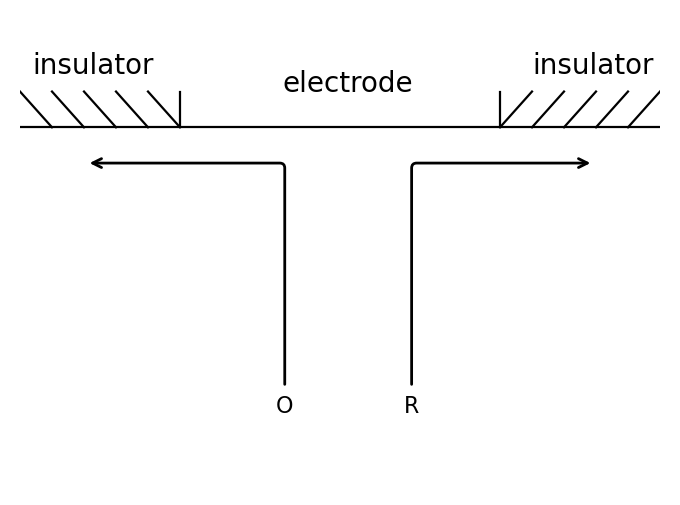

In [11]:
fig = plt.figure()
ax = plt.subplot(111)
ax.set_xlim(0, 1)
ax.set_ylim(0,1.3)
ax.grid(visible=False)
ax.axes.set_axis_off()
ax.plot([0, 1], [1, 1], 
        [0.25, 0.25], [1., 1.1], 
        [0.75, 0.75], [1., 1.1],
        c='black')
for i in range(5):
    plt.plot([0.05*i, 0.05+0.05*i], [1.1, 1.], 'black')
    plt.plot([0.75+0.05*i, 0.8+0.05*i], [1., 1.1], 'black')

ax.annotate('electrode', (0.41, 1.1))    
ax.annotate('insulator', (0.02, 1.15))    
ax.annotate('insulator', (0.8, 1.15))    

ax.annotate('O', fontsize=8,
            xy=(0.1, 0.9), xycoords='data', 
            xytext=(0.4, 0.2), textcoords='data', 
            arrowprops=dict(arrowstyle='->', color='black',
            connectionstyle="angle,angleA=-90,angleB=180,rad=5")
           )

ax.annotate('R', fontsize=8,
            xy=(0.9, 0.9), xycoords='data', 
            xytext=(0.6, 0.2), textcoords='data', 
            arrowprops=dict(arrowstyle='->', color='black',
            connectionstyle="angle,angleA=90,angleB=180,rad=5")
           )

fig.savefig('../Workspace/convection.png')

## Convection

The movement of species in solution can be facilitated by mixing. As any chemist knows, the more controlled and uniform the mixing, the better the outcome! 

<div class="alert alert-block alert-success">
<b>Convection:</b> Movement due to physical mixing of the solution by some perturbation, such as stirring or pumping of the electrolyte solution.
</div>

Mathematically, convection is the  velocity of the species involved:

$
\large J_j(x,t) = C_j \nu_j(x,t)
$

Where:
- $C_j$: concentration of species of interest
- $\nu_j(x,t)$: the velocity of the species of interest in time and space

Convection can be extremely useful in electrochemical experiments, assuming you have control over it. We will see several techniques that strategically control convection in order to facilitate analyses.

# 2. Concentration Profiles

The basic tool for understanding mass transfer is the **concentration profile**. These graphs show the normalized concentration of the reactant and product. Consider the standard generalized reaction:

$
\large O + e^- \rightleftharpoons R
$

The concentration of the two species in **bulk solution** is represented by $C_R^*$ and $C_O^*$. Because the two species are linked by a reaction, it can be stated that the total concentration ($C_T^*$) is the sum of the two:

$
\large C_T^* = C_R^* + C_O^*
$

This provides an easy way to normalize the concentrations:

$
\large 1 = \frac{C_R^*}{C_T^*} + \frac{C_O^*}{C_T^*}
$

A **concentration profile** plots both $C_R/C_T^*$ and $C_O/C_T^*$ against distance from the electrode:

<div class="alert alert-block alert-info">
<b>Activity:</b> The diagram below shows a concentration profile on an undisturbed solution resting at open-circuit potential. Familiarize yourself with the diagram and ensure you understand it. Then attempt to sketch what would happen if the system is perturbed by applying the following voltages:
    <br>
    1. $E = E^{0'}$
    <br>
    2. $E << E^{0'}$
</div>

In [12]:
@interact(c_o_bulk=widgets.FloatText(value=0.003, step=0.0001, description=r'$C_O^*$'),
          c_r_bulk=widgets.FloatText(value=0.0, step=0.0001, description=r'$C_R^*$'))
def plot_resting_profile(c_o_bulk, c_r_bulk):
    '''An undisturbed solution at open circuit: flat profiles, no gradient, no current.'''
    if c_o_bulk + c_r_bulk <= 0:
        print('At least one concentration must be greater than zero.')
        return
    x = np.linspace(0, 1., 100)
    c_t = c_o_bulk + c_r_bulk

    fig = plt.figure()
    ax = plt.subplot()
    ax.set_ylim(-0.1, 1.1)
    ax.set_xlim(x.min(), 1.12)
    ax.set_xlabel(r'$x$ (distance from electrode)')
    ax.set_xticks([0])
    ax.set_ylabel(r'$C_j/C_T^*$')

    ax.plot(x, np.full(x.size, c_o_bulk/c_t), 'red')
    ax.plot(x, np.full(x.size, c_r_bulk/c_t), 'blue')
    ax.annotate(r'$\frac{C_O}{C_T^*}$', (1.05, c_o_bulk/c_t), color='red')
    ax.annotate(r'$\frac{C_R}{C_T^*}$', (1.05, c_r_bulk/c_t), color='blue')

interactive(children=(FloatText(value=0.003, description='$C_O^*$', step=0.0001), FloatText(value=0.0, descrip…

Application of a voltage to the electrode forces a new equilibrium onto the solution - but only at the electrode surface. The $C_j/C_T^*$ terms will therefore rapidly change to new values, with the numeric value dictated by the **Nernst equation**. This change is initially highly localized, resulting in a steep concentration gradient. This leads to rapid diffusion, which forces what is referred to as a **diffusion layer** to grow into solution.

<div class="alert alert-block alert-success">
<b>Diffusion layer:</b> A region within the electrolyte solution wherein the concentration differs from those of bulk solution. Not to be confused with electrical double layer.
</div>

# 3. Calculating/Approximating Mass Transfer

The basic concept behind mass transfer is that the total flux (movement) of a species is affected by diffusion, migration and convection:

(Flux of species j) = (diffusion of j) + (migration of j) + (convection of j)

Mathematically, we can combine the equations from section 1:

$
\large J_j(x,t) = -D_j\frac{\delta C_j(x,t)}{\delta x} - \frac{z_j F}{RT}D_jC_j\frac{\delta\phi(x,t)}{\delta x} + C_j \nu_j(x,t)
$

In practice, we often work under such conditions that either:
1. migration and convection are negligible, leaving only diffusion to be of relevance
2. the solution is mixed such that migration and diffusion become negligible, leaving convection to be dominant

In [13]:
# A measured dimensionless concentration profile.  Column 0 is x/sqrt(D t), so
# multiplying by sqrt(D t) turns it into a real distance for any D and t.
data = np.genfromtxt('../Resources/data/conc_profile.csv', delimiter=',', skip_header=1)
x_dimensionless = data[:, 0]
c_reduced = data[:, 1]
c_oxidized = data[:, 2]

@interact(diff=widgets.FloatText(value=0.001, step=0.001, description=r'$D_{j,1}$'),
          time=widgets.FloatText(value=0.001, step=0.001, description=r'$t_1$'),
          diff2=widgets.FloatText(value=0.001, step=0.001, description=r'$D_{j,2}$'),
          time2=widgets.FloatText(value=0.001, step=0.001, description=r'$t_2$'))
def plot_concentration_profile(diff, time, diff2, time2):
    '''The same shape every time.  Only the distance scale, sqrt(D t), changes.'''
    if min(diff, time, diff2, time2) <= 0:
        print('D and t must all be greater than zero.')
        return
    fig = plt.figure()
    ax = plt.subplot()

    distance = x_dimensionless*np.sqrt(diff*time)
    distance2 = x_dimensionless*np.sqrt(diff2*time2)
    ax.plot(distance, c_reduced, label=r'$C_R/C_T^*$', c='black')
    ax.plot(distance, c_oxidized, label=r'$C_O/C_T^*$', c='red')
    ax.plot(distance2, c_reduced, c='black', linestyle=':')
    ax.plot(distance2, c_oxidized, c='red', linestyle=':')

    ax.set_xlabel('distance /cm')
    ax.set_xlim(left=0, right=max(distance.max(), distance2.max()))
    ax.set_ylabel(r'$C_j/C_T^*$')
    ax.set_ylim(-0.1, 1.1)
    ax.legend(fontsize=6, loc=4)

interactive(children=(FloatText(value=0.001, description='$D_{j,1}$', step=0.001), FloatText(value=0.001, desc…

The data that is loaded for the figure above shows the *dimensionless* concentration gradient following a voltage step from $E_{OC}$ to $E <<E^0$ using a macrodisc electrode. This behavior is a characteristic behavior that *all* systems will follow under the same circumstances. The single curve can therefore be used to determine the diffusion layer thickness for any system under these circumstances.

For those interested, see Appendix B in *Electrochemical Methods: Fundamentals and Applications*, Allen J. Bard & Larry R. Faulkner.

The figure above raises the question: **how thick is the diffusion layer?** This is a critical question because the diffusion layer may very well limit the rate of electron transfer reactions at the electrode surface. As the diffusion layer builds up, the reacting molecules must travel from farther and farther away from the electrode surface.

## Semi-empirical Treatment

If there is no migration affecting the system, the most straightforward approach is to simply approximate the gradient of the concentration profile as a linear slope. The **diffusion layer thickness**, $\delta_j$, is then taken as the intercept with an extrapolated line for the bulk solution. The linear approximation then makes it possible to define the concentration gradient as a single linear slope:

$
\large J_j(t) = D_j\frac{[C_j^* - C_j(0,t)]}{\delta_j}
$

Note that this equation is still **time-dependent**. The flux will decrease with time!

It is useful to define a new parameter here: the **mass-transfer coefficient**, $m_j$:

$
\large m_j = \frac{D_j}{\delta_j}
$

With this definition, the flux is simplified as:

$
\large J_j(t) = m_j[C_j^* - C_j(0,t)]
$

<div class="alert alert-block alert-danger">
<b>Unit Check!</b> What units does $m_j$ have?
</div>

The rate of an electron transfer reaction, which is embodied in the current that is measured, can be limited by kinetics or mass transfer. The utility of the mass-transfer coefficient therefore becomes apparent - if electron transfer is limited by mass transfer, then the reaction rate is equal to the mass flux:

$
\large J_j(t) = \frac{i(t)}{nFA}
$

It can therefore be written that:

$
\large \frac{i_c}{nFA} = m_O[C_O(0,t)-C_O^*]
$

$
\large \frac{i_a}{nFA} = m_R[C_R^*-C_R(0,t)]
$

The limit of this behavior is reached at large anodic or cathodic overpotentials, where the Nernst equation dictates 100% conversion at the electrode surface. Under this situation, $C_j(0,t) = 0$ for the reactant. This yields current-limiting behavior

$
\large i_{lim,c} = -nFAm_OC_O^*
$

$
\large i_{lim,a} = nFAm_RC_R^*
$

These two equations describe the individual anodic and cathodic portions of the behavior. The total limiting current spans from $i_{lim,c}$ to $i_{lim,a}$:

$
\large i_{lim} = i_{lim,a} - i_{lim,c}
$

**OR**

$
\large i_{lim} = i_{lim,c} - i_{lim,a}
$

**Note:** the $\Delta C_j$ parameters can be defined this way, or reversed. The net effect is to change between the conventions where anodic current is positive, or cathodic current is positive. The math below defines anodic currents as positive.

It is important to remember that $m_O$ and $m_R$ are not constant - $\delta_j$ increases with time, so $m_j$ will decrease with time. The limiting current values above are therefore NOT constants for a system! 

# 4. Combining Mass Transfer Coefficients and Thermodynamics

Isolation of $C_j^*$ in the limiting-current equations above and substitution into the original equations yields (Notice that the time-dependence has been removed!):

$
\large C_O(x=0) = \frac{i-i_{lim,c}}{nFAm_O}
$

$
\large C_R(x=0) = \frac{i_{lim,a}-i}{nFAm_R}
$

These forms of the equation allow a small trick. Consider the Nernst equation:

$
\large E = E^{0'} - \frac{RT}{nF}ln\left[ \frac{C_R(x=0)}{C_O(x=0)} \right]
$

Substitution of both mass transfer limited equations into the Nernst equation yields:

$
\large E = E^{0'} - \frac{RT}{nF}ln\left[ \frac{m_O}{m_R} \right] + \frac{RT}{nF}ln\left[ \frac{i - i_{lim,c}}{i_{lim,a}-i} \right]
$

Visualization of this situation for the condition where $C_R^*/C_T = 1.0$:

In [14]:
@interact(m_ratio=widgets.FloatText(value=10.0, step=0.2, description=r'$m_O/m_R$'),
          i_lim_c=widgets.BoundedFloatText(value=-0.2, min=-2.0, max=-0.01, step=0.01,
                                           description=r'$i_{lim,c}$'),
          i_lim_a=widgets.BoundedFloatText(value=0.8, min=0.01, max=2.0, step=0.01,
                                           description=r'$i_{lim,a}$'))
def plot_mass_transfer_ratio(m_ratio, i_lim_c, i_lim_a):
    '''Unequal delivery of O and R shifts the half wave potential away from E0'.'''
    if m_ratio <= 0:
        print('The ratio m_O/m_R must be greater than zero.')
        return
    fig = plt.figure()
    ax = plt.subplot()
    ax.set_xlabel(r"$E$ /V vs. $E^{0'}$")
    ax.set_ylabel(r'$i/i_{lim}$')

    half_point = (i_lim_c + i_lim_a) / 2
    current = np.linspace(i_lim_c + 0.001, i_lim_a - 0.0001, 400)

    for ratio in [1.0, m_ratio]:
        potential = (-f**-1*np.log(ratio)
                     + f**-1*np.log((current - i_lim_c)/(i_lim_a - current)))
        ax.plot(potential, current, label=rf'$m_O/m_R$ = {ratio:.1f}')

    idx_half = echem.nearest_index(current, half_point)
    ax.axvline(potential[idx_half], linestyle=':', c='red')
    ax.annotate(rf'$E_{{1/2}}$={potential[idx_half]:.3f}', xy=(0.65, 0.55),
                xycoords='axes fraction', c='red')
    ax.axvline(0, linestyle=':', color='black')
    ax.axhline(half_point, linestyle=':', color='gray')
    ax.legend(fontsize=6)

interactive(children=(FloatText(value=10.0, description='$m_O/m_R$', step=0.2), BoundedFloatText(value=-0.2, d…

Exploration of the figure above should convince you that changes in the relative magnitude of $m_O$ to $m_R$ result a shift in the **half-wave potential**, $E_{1/2}$:

$
\large E_{1/2} = E^{0'} - \frac{RT}{nF}ln\left[ \frac{m_O}{m_R} \right]
$

# 5. Combining Mass Transfer with the Current-Overpotential Equation

Recall the current-overpotential equation:

$
\large i = i_0 \left[ \frac{C_R(0,t)}{C_R^*} e^{(1-\alpha) F \eta / R T} -  \frac{C_O(0,t)}{C_O^*} e^{-\alpha F \eta / R T} \right]
$

To substitute mass-transfer limited currents as parameters into this equation we need to substitute $C_j/C_j^*$. The two equations of use are:

$
\large |i_{lim,j}| = nFAm_jC_j^*
$

$
\large i_j = nFAm_j[C_j^* - C_j(0,t)]
$

Combining these two equations yields:

$
\large \frac{C_j(0,t)}{C_j^*} = 1-\frac{i}{i_{lim,j}}
$

Therefore, with anodic currents defined as positive:

$
\large i = i_0 \left[ \left( 1-\frac{i}{i_{lim,a}}\right)e^{(1-\alpha) F \eta/RT} - \left(1-\frac{i}{i_{lim,c}}\right) e^{-\alpha F \eta/RT} \right]
$

With this form of the equation, we now see the explicit mass transfer limitations, in conjunction with the thermodynamics and the kinetics. Be sure you recognize which parameters represent each!

---
# Literature Examples



The exact structure of the electrical double layer, and its response to changes in chemistry at the surface remains a matter of research interest. Vibrational spectroscopy serves as an important tool in such studies. The **vibrational Stark effect** is the underlying phenomenon that makes this approach powerful: electric fields induce a shift in vibrational frequency, allowing measurement of localized electric fields.

[2017 J. Phys. Chem. C 121, 11585](https://pubs.acs.org/doi/abs/10.1021/acs.jpcc.7b03134)

<img src='../Resources/images/2017JPCC.PNG' width=50%>

Localized electric fields are critical to the function of photovoltaics, such as the modern **perovskite solar cells**. This class of device skyrocketed from obscure technology to world-leading technology in a matter of years. These devices have proven to be an interesting playground for physical chemistry.

[2016 Energy & Environ. Sci. 9, 1476](https://pubs.rsc.org/en/content/articlelanding/2016/ee/c5ee02740c)

<img src='../Resources/images/2016EES.png' width=50%>